<a href="https://colab.research.google.com/github/leejsya/MLProgramming/blob/main/week8/DL_Mobile_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#### Library & Module Import

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torch.optim as optim

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#### Preprocessing

In [ ]:
df = pd.read_csv("./mobile.csv")
df.head()

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1


In [ ]:
# 결측값 확인
df.isna().sum()

battery_power    0
blue             0
clock_speed      0
dual_sim         0
fc               0
four_g           0
int_memory       0
m_dep            0
mobile_wt        0
n_cores          0
pc               0
px_height        0
px_width         0
ram              0
sc_h             0
sc_w             0
talk_time        0
three_g          0
touch_screen     0
wifi             0
price_range      0
dtype: int64

Text(0, 0.5, 'count')

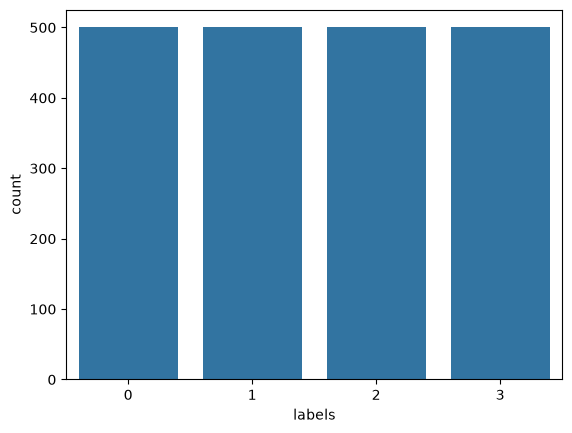

In [ ]:
# 클래스별 데이터 분포 확인
sns.countplot(data=df, x='price_range')
plt.xlabel('labels')
plt.ylabel('count')

In [ ]:
df['price_range'].value_counts()

price_range
1    500
2    500
3    500
0    500
Name: count, dtype: int64

In [ ]:
# input, target 설정
X = df.drop('price_range', axis=1)
y = df['price_range']

print(X.head())
print("\n")
print(y.head())

   battery_power  blue  clock_speed  dual_sim  fc  four_g  int_memory  m_dep  \
0            842     0          2.2         0   1       0           7    0.6   
1           1021     1          0.5         1   0       1          53    0.7   
2            563     1          0.5         1   2       1          41    0.9   
3            615     1          2.5         0   0       0          10    0.8   
4           1821     1          1.2         0  13       1          44    0.6   

   mobile_wt  n_cores  pc  px_height  px_width   ram  sc_h  sc_w  talk_time  \
0        188        2   2         20       756  2549     9     7         19   
1        136        3   6        905      1988  2631    17     3          7   
2        145        5   6       1263      1716  2603    11     2          9   
3        131        6   9       1216      1786  2769    16     8         11   
4        141        2  14       1208      1212  1411     8     2         15   

   three_g  touch_screen  wifi  
0        0 

In [ ]:
# feature 개수 확인
len(X.columns)

20

In [ ]:
# 시드 고정
seed = 42

# 6 : 2 : 2로 train/val/test 분할
X_temp, X_test, y_temp, y_test = train_test_split(X, y,
                                                test_size=0.2,
                                                stratify=y,
                                                random_state=seed)

X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp,
                                                test_size=0.25,
                                                stratify=y_temp,
                                                random_state=seed)


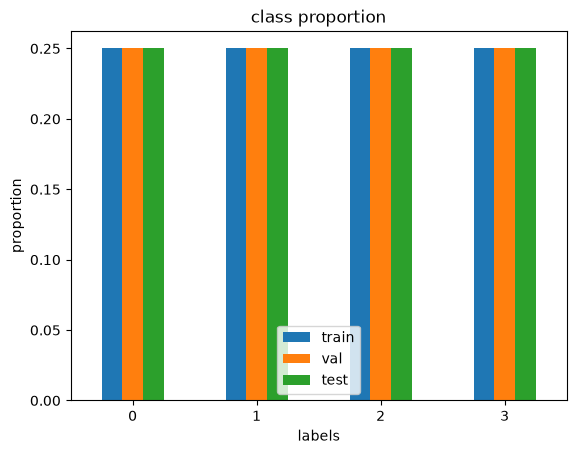

In [ ]:
# train/val/test가 균일한 데이터로 잘 분할되었는지 비율 확인
train_prop = y_train.value_counts(normalize=True).sort_index()
val_prop = y_val.value_counts(normalize=True).sort_index()
test_prop = y_test.value_counts(normalize=True).sort_index()

prop_df = pd.DataFrame(
    {
        'train': train_prop,
        'val': val_prop,
        'test': test_prop
    }
)
prop_df.plot.bar(rot=0)
plt.xlabel('labels')
plt.ylabel('proportion')
plt.title('class proportion')
plt.show()

In [ ]:
# Standardization
scaler = StandardScaler()
scaler.fit(X_train)

X_train_scaled = scaler.transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

#### Dataset

In [ ]:
class MobileDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y.to_numpy()

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):
        X_tensor = torch.tensor(self.X[index], dtype=torch.float32)
        y_tensor = torch.tensor(self.y[index], dtype=torch.long)

        return X_tensor, y_tensor


train_dataset = MobileDataset(X_train_scaled, y_train)
val_dataset = MobileDataset(X_val_scaled, y_val)
test_dataset = MobileDataset(X_test_scaled, y_test)

#### DataLoader

In [ ]:
torch.manual_seed(seed)
train_dataloader = DataLoader(
    dataset=train_dataset,
    batch_size=32,
    shuffle=True,
    drop_last=True
)
val_dataloader = DataLoader(
    dataset=val_dataset,
    batch_size=32,
)
test_dataloader = DataLoader(
    dataset=test_dataset,
    batch_size=32,
)

#### Model

In [ ]:
class MobileModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(20, 32)
        self.fc2 = nn.Linear(32, 16)
        self.fc3 = nn.Linear(16, 8)
        self.fc4 = nn.Linear(8, 4)
        self.dropout = nn.Dropout()
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        x = self.relu(x)
        x = self.fc3(x)
        x = self.relu(x)
        x = self.dropout(x)
        x = self.fc4(x)
        return x

#### Setup

In [ ]:
model = MobileModel()
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

In [ ]:
device = torch.device(
    'cuda' if torch.cuda.is_available()
    else 'mps' if torch.backends.mps.is_available()
    else 'cpu'
)
model.to(device)
print(device)

mps


#### Validation & Test function

In [ ]:
def evaluate(dataloader, model, loss_fn):
    model.eval()
    # loss값을 저장하는 리스트
    losses = []
    # 모델이 맞춘 개수
    correct = 0
    # 총 개수
    total = 0
    # 모든 예측값 리스트
    all_preds = []
    # 모든 라벨값 리스트
    all_labels = []
    with torch.no_grad():
        for batch in dataloader:
            inputs, labels = batch[0].to(device), batch[1].to(device)
            preds = model(inputs)
            loss = loss_fn(preds, labels)
            # loss 벡터를 losses 리스트에 넣음.
            losses.append(loss.item())
            # 확률이 가장 높은 클래스를 예측값으로
            pred_labels = torch.argmax(preds, dim=1)
            # 예측값과 라벨값이 같은 횟수를 더하여 저장.
            correct += (pred_labels == labels).sum().item()
            # 총 예측값 개수를 더하여 저장
            total += len(preds)

            # 각 배치의 예측값 텐서를 리스트에 저장
            all_preds.append(pred_labels.cpu())
            # 각 배치의 라벨값 텐서를 리스트에 저장
            all_labels.append(labels.cpu())

    # 각 배치의 예측값 텐서들을 행으로 이어붙임.
    all_preds = torch.cat(all_preds)
    # 각 배치의 라벨값 텐서들을 행으로 이어붙임.
    all_labels = torch.cat(all_labels)

    avg_loss = sum(losses) / len(losses)
    acc = correct / total

    return avg_loss, acc, all_preds, all_labels

#### Train Loop function

In [ ]:
def Train_Loop(dataloader, model, loss_fn, epochs, optimizer, min_loss):
    step = 0
    # 각 배치의 평균 loss값을 저장하는 리스트
    loss_history = []
    # 각 배치의 평균 acc값을 저장하는 리스트
    acc_history = []

    model.train()
    for epoch in range(epochs):
        for batch in dataloader:
            inputs, labels = batch[0].to(device), batch[1].to(device)
            preds = model(inputs)
            loss = loss_fn(preds, labels)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            step += 1
            if step % 10 == 0:
                print(f"(step {step}) train loss: {loss.item():.4f}")

        val_loss, val_acc, all_preds, all_labels = evaluate(
            val_dataloader,
            model,
            loss_fn
        )
        # 평균 loss값 추가
        loss_history.append(val_loss)
        # 평균 acc값 추가
        acc_history.append(val_acc)
        print(f"[epoch {epoch+1}/{epochs}] val loss: {val_loss:.4f}, val acc: {val_acc:.4f}\n")

        # val_loss가 가장 작을 때의 모델을 저장
        if min_loss >= val_loss:
            min_loss = val_loss
            torch.save(model.state_dict(), 'model2.pt')

    return min_loss, loss_history, acc_history, all_preds, all_labels

#### Training

In [ ]:
# min_loss를 무한한 양의 실수로 초기화
min_loss = float('inf')

# epochs=30으로 모델 training
min_loss, loss_history, acc_history, all_preds, all_labels = Train_Loop(
    train_dataloader,
    model,
    loss_fn,
    epochs=30,
    optimizer=optimizer,
    min_loss=min_loss,
)

(step 10) train loss: 1.3231
(step 20) train loss: 1.3328
(step 30) train loss: 0.7926
[epoch 1/30] val loss: 0.7251, val acc: 0.6200

(step 40) train loss: 0.7941
(step 50) train loss: 0.4996
(step 60) train loss: 0.3544
(step 70) train loss: 0.2677
[epoch 2/30] val loss: 0.2768, val acc: 0.8825

(step 80) train loss: 0.2970
(step 90) train loss: 0.3952
(step 100) train loss: 0.2034
(step 110) train loss: 0.3248
[epoch 3/30] val loss: 0.2564, val acc: 0.8925

(step 120) train loss: 0.1890
(step 130) train loss: 0.0831
(step 140) train loss: 0.1678
[epoch 4/30] val loss: 0.1984, val acc: 0.9250

(step 150) train loss: 0.0872
(step 160) train loss: 0.1303
(step 170) train loss: 0.2007
(step 180) train loss: 0.1698
[epoch 5/30] val loss: 0.2297, val acc: 0.9000

(step 190) train loss: 0.1985
(step 200) train loss: 0.0314
(step 210) train loss: 0.1241
(step 220) train loss: 0.0843
[epoch 6/30] val loss: 0.1837, val acc: 0.9225

(step 230) train loss: 0.0451
(step 240) train loss: 0.1043
(

#### Test

In [ ]:
# best model 생성
best_model = MobileModel().to(device)
# 성능이 가장 좋았을 때의 상태를 best_model에 대입
best_model.load_state_dict(torch.load('model2.pt'))
test_loss, test_acc, _, _ = evaluate(
    test_dataloader,
    best_model,
    loss_fn
)
print(f"test loss: {test_loss:.4f}, test acc: {test_acc:.4f}")

test loss: 0.1683, test acc: 0.9275


#### Metrics

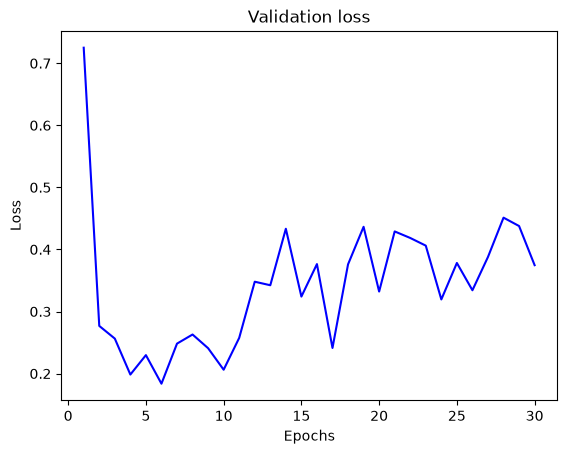

In [ ]:
# 학습 중 epoch에 따라 loss의 변화를 기록하여 나타낸 그래프
plt.plot(range(1, len(loss_history)+1), loss_history, 'b', label="Validation loss")
plt.title("Validation loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.show()

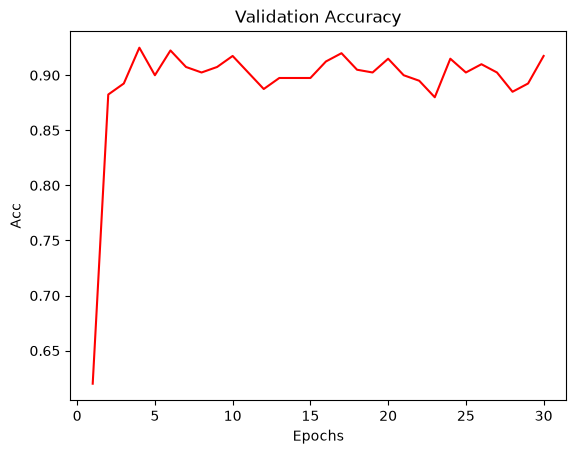

In [ ]:
# 학습 중 epoch에 따라 accuracy의 변화를 기록하여 나타낸 그래프
plt.plot(range(1, len(acc_history)+1), acc_history, 'r', label="Validation accuracy")
plt.title("Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Acc")
plt.show()

In [ ]:
report = classification_report(
    all_labels, all_preds,
    output_dict=True
)
print(classification_report(all_labels, all_preds))

              precision    recall  f1-score   support

           0       0.92      0.97      0.95       100
           1       0.90      0.88      0.89       100
           2       0.89      0.89      0.89       100
           3       0.96      0.93      0.94       100

    accuracy                           0.92       400
   macro avg       0.92      0.92      0.92       400
weighted avg       0.92      0.92      0.92       400



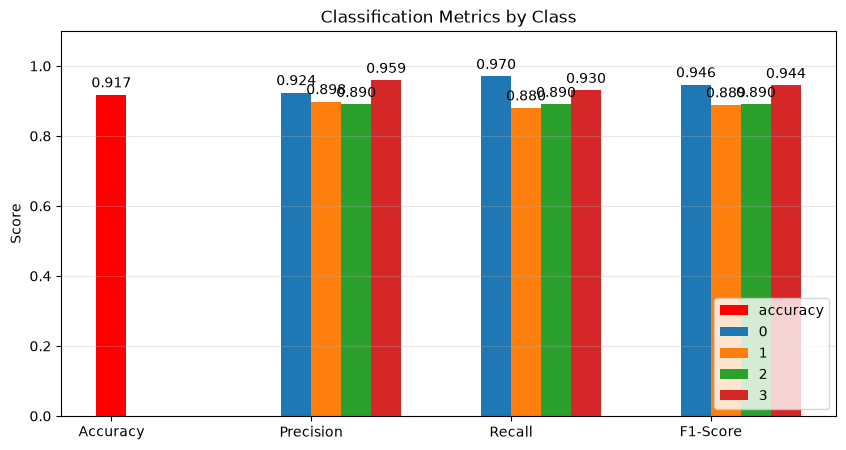

In [ ]:
classes = ['0', '1', '2', '3']
metrics = ['precision', 'recall', 'f1-score']
accuracy = report['accuracy']

x = np.arange(len(metrics)) + 1
width = 0.15

fig, ax = plt.subplots(figsize=(10,5))

acc_bar = ax.bar(0, accuracy, width, color='r', label='accuracy')
ax.bar_label(acc_bar, fmt='%.3f', padding=3)

for i, cls in enumerate(classes):
    values = [report[cls][m] for m in metrics]
    bars = ax.bar(x + (i - 0.5) * width, values, width, label=cls)
    ax.bar_label(bars, fmt='%.3f', padding=3)

ax.set_xticks(np.arange(len(metrics) + 1), ['Accuracy', 'Precision', 'Recall', 'F1-Score'])
ax.set_ylabel('Score')
ax.set_ylim(0, 1.1)
ax.set_title('Classification Metrics by Class')
ax.legend(loc='lower right')
ax.grid(axis='y', alpha=0.3)
plt.show()